# Does YaRN help a 2K model read 4K?

**Exploratory WikiText pilot · original SmolLM-135M · fixed pretrained weights**

Compare ordinary RoPE and static YaRN ×2 at 2,048 and 4,096 input tokens.
All four conditions predict the **same final 512 targets per article**.
The short input is the exact 2K suffix of the long input.

This notebook preserves the reviewed pilot’s model, data, scoring and checks.
The submitted eager-attention result on G5’s frozen corpus is a separate
experiment: see [the submission plan](../docs/long_context_plan.md) and
[its actual test log](../results/context_extension/TEST_LOG.md).
Do not combine the two studies’ losses or interpret pilot timings as team-model speed.


## Run this notebook

Use a CUDA GPU supporting BF16 and Python 3.13 or newer. Install the adjacent
`requirements-context-extension.txt`, select the Python kernel, then **Run All**.
The first run downloads the pinned public checkpoint and WikiText test split.
No training or checkpoint updates occur. New evidence is written below the
kernel’s current working directory in `out/context_extension_pilot/`.

Tables and charts use standard notebook outputs. The recorded submission
measurements remain unchanged when this notebook is rerun.


## Recorded pilot results

These measurements come from the original GPU run on **18 November 2026 IST**
(`2026-11-17T19:29:18.881325+00:00` UTC). They are a saved snapshot, not outputs
from a new execution of this converted notebook. The sandbox connection was
unavailable during conversion; code cells are intentionally unexecuted.
Run All on CUDA to create fresh outputs below the code cells.

| Run | Rotary method | Input tokens | Mean NLL ↓ | Perplexity ↓ |
|---|---|---:|---:|---:|
| A | Original RoPE | 2048 | 2.470164 | 11.824388 |
| B | Original RoPE | 4096 | 6.693264 | 806.952112 |
| C | YaRN ×2 | 4096 | 2.482160 | 11.967088 |
| D | YaRN ×2 | 2048 | 2.470355 | 11.826650 |

YaRN recovers most of the loss caused by using ordinary 2K RoPE at 4K.
Holding YaRN fixed, 4K minus 2K is **+0.011805 nats/token**: the extra prefix
does not improve mean loss on these three suffixes. This does not establish
a general limit on long-context usefulness.

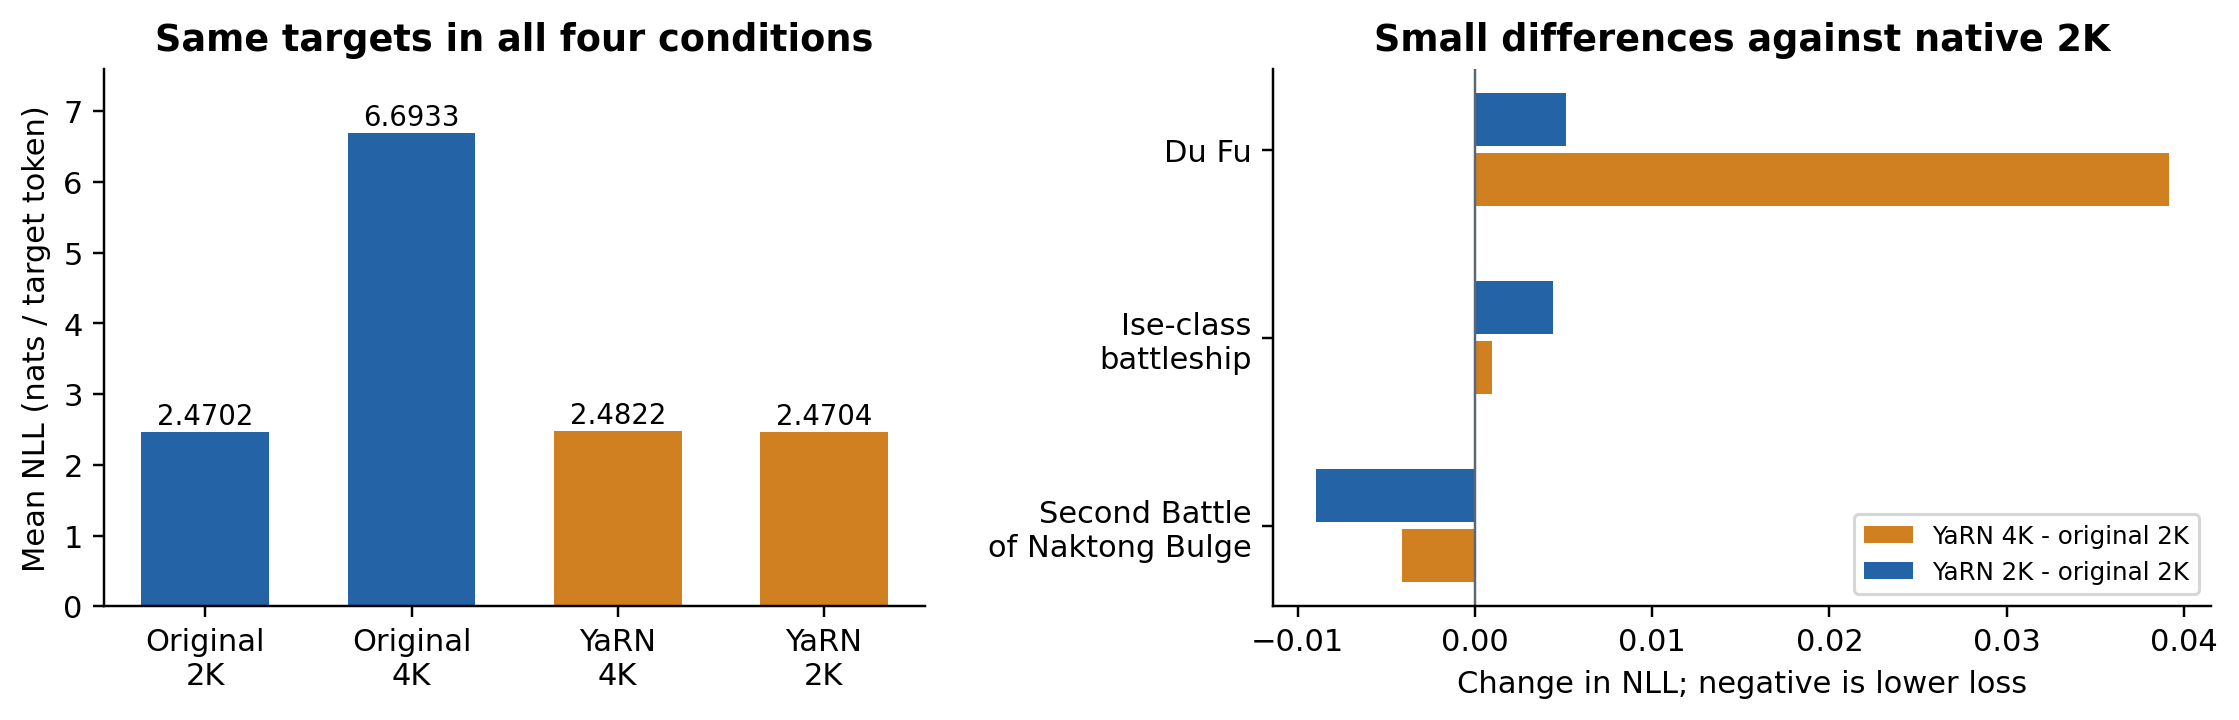

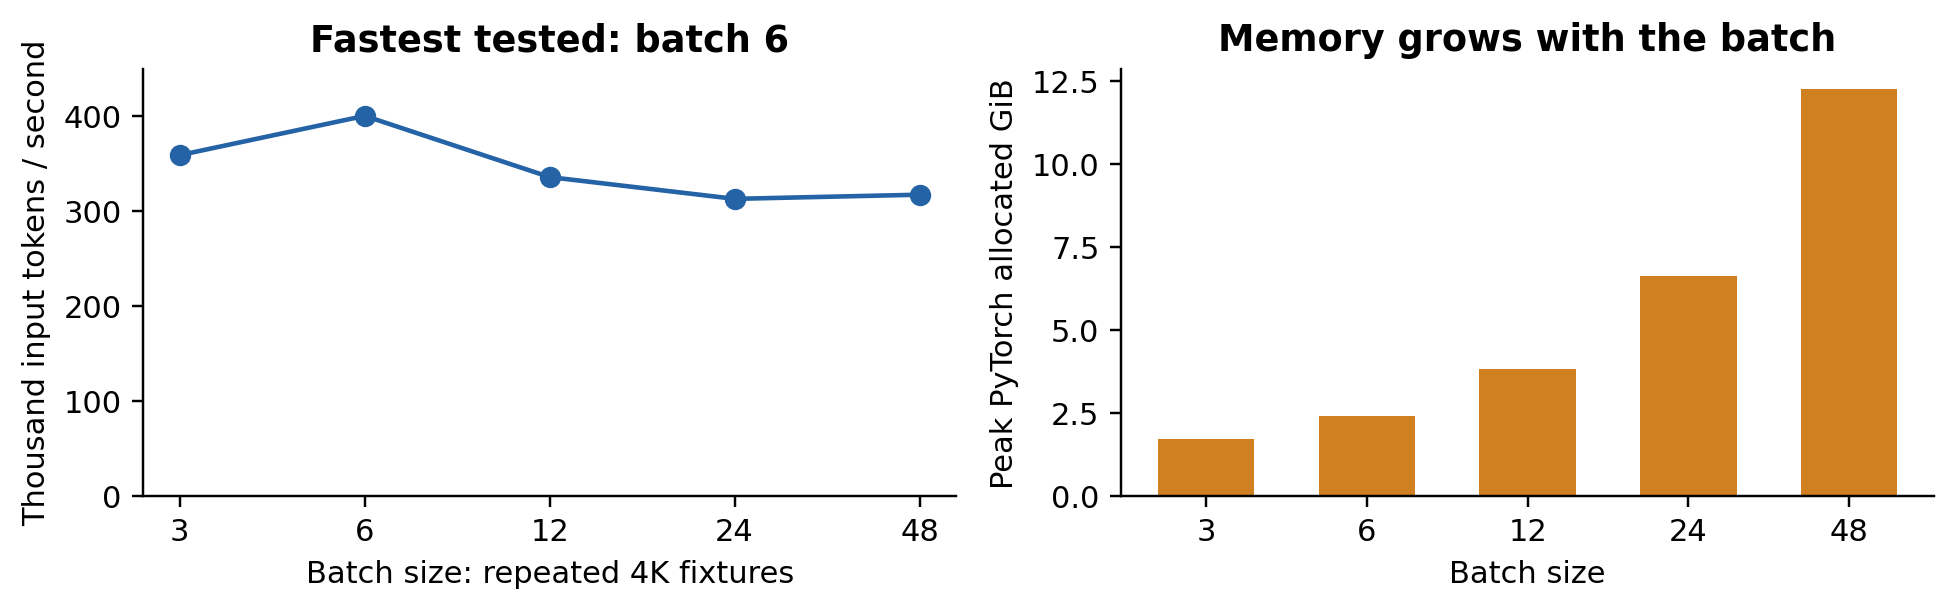

The batch sweep repeats these same three fixtures; it adds no quality samples.
Fastest tested batch: **6**, about **400,418 input tokens/s**, with **2,475.6 MiB**
peak allocated memory. These are forward-plus-tail-loss measurements.
The saved CSVs and full timing scope are in the [pilot log](../results/context_extension/PILOT_TEST_LOG.md).


In [ ]:
import torch
import torch.nn.functional as F
import transformers
import pandas as pd
import altair as alt
import numpy as np
import json
import hashlib
import math
import time
import copy
import os
import platform
import importlib.metadata
from pathlib import Path
from datasets import load_dataset
from transformers import AutoConfig, AutoTokenizer, AutoModelForCausalLM
from huggingface_hub.utils import disable_progress_bars

disable_progress_bars()
torch.manual_seed(1234)
torch.set_num_threads(16)
torch.set_float32_matmul_precision("highest")
alt.theme.enable("default")
import datetime
from IPython.display import display, Markdown, SVG, Image, JSON
import vl_convert as vlc


def chart_image(chart):
    """Static PNG output renders in both Jupyter and GitHub."""
    return Image(data=vlc.vegalite_to_png(chart.to_dict(), scale=2))


## Experiment settings

Model and dataset revisions are fixed. The same precision and backend are used in all four main comparisons.


In [ ]:
MODEL_ID = "HuggingFaceTB/SmolLM-135M"
MODEL_REVISION = "1d461723eec654e65efdc40cf49301c89c0c92f4"
DATASET_ID = "Salesforce/wikitext"
DATASET_REVISION = "b08601e04326c79dfdd32d625aee71d232d685c3"
NATIVE_LENGTH = 2048
LONG_LENGTH = 4096
TAIL_LENGTH = 512
DOCUMENT_COUNT = 3
TIMING_REPEATS = 3
DEVICE = "cuda"
DTYPE = torch.bfloat16
ARTIFACT_DIR = Path.cwd() / "out" / "context_extension_pilot"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
assert torch.cuda.is_available(), "This notebook expects the allocated CUDA sandbox."
assert (
    torch.cuda.is_bf16_supported()
), "Use a consistent supported dtype across all runs."
hardware = {
    "gpu": torch.cuda.get_device_name(0),
    "vram_gib": round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2),
    "visible_vcpus": len(os.sched_getaffinity(0)),
    "visible_ram_gib": round(
        os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30, 1
    ),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "cuda": torch.version.cuda,
}
for _label, _file in [
    ("container_memory_limit", "memory.max"),
    ("container_cpu_quota", "cpu.max"),
]:
    _path = Path("/sys/fs/cgroup") / _file
    if _path.exists():
        hardware[_label] = _path.read_text().strip()
display(
    Markdown(
        f"**{hardware['gpu']}** · {hardware['vram_gib']:.1f} GiB VRAM · BF16 · batched SDPA scoring"
    )
)


## Load the two rotary configurations

Both models load the same pretrained parameters. Only the rotary configuration and allowed context differ.


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
base_config = AutoConfig.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
assert base_config.max_position_embeddings == NATIVE_LENGTH
assert base_config.num_attention_heads == 9 and base_config.num_key_value_heads == 3
yarn_config = copy.deepcopy(base_config)
yarn_config.max_position_embeddings = LONG_LENGTH
yarn_config.rope_parameters = {
    "rope_type": "yarn",
    "rope_theta": 10000.0,
    "factor": 2.0,
    "original_max_position_embeddings": NATIVE_LENGTH,
    "beta_fast": 32.0,
    "beta_slow": 1.0,
}
native_model = (
    AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        revision=MODEL_REVISION,
        config=base_config,
        dtype=DTYPE,
        attn_implementation="sdpa",
    )
    .to(DEVICE)
    .eval()
)
yarn_model = (
    AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        revision=MODEL_REVISION,
        config=yarn_config,
        dtype=DTYPE,
        attn_implementation="sdpa",
    )
    .to(DEVICE)
    .eval()
)
models = {"Original RoPE": native_model, "YaRN ×2": yarn_model}
parameter_count = sum((p.numel() for p in native_model.parameters()))


## Select fixed evaluation documents

Select the first three complete test articles with at least 4K tokens before scoring. Pretraining overlap is unknown.


In [ ]:
def select_documents(rows, tokenizer, count, length):
    selected = []
    article_title, paragraphs = ("", [])

    def consider(title, paragraphs):
        text = "\n".join(paragraphs).strip()
        ids = tokenizer(text, add_special_tokens=False, truncation=False)["input_ids"]
        if title and len(ids) >= length:
            selected.append(
                {
                    "title": title,
                    "available_tokens": len(ids),
                    "ids": ids[:length],
                    "text_sha256": hashlib.sha256(text.encode()).hexdigest(),
                    "tokens_sha256": hashlib.sha256(
                        json.dumps(ids[:length]).encode()
                    ).hexdigest(),
                }
            )

    for row in rows:
        line = row["text"].strip()
        new_article = (
            line.startswith("= ")
            and line.endswith(" =")
            and (not line.startswith("= ="))
        )
        if new_article:
            consider(article_title, paragraphs)
            if len(selected) == count:
                return selected
            article_title, paragraphs = (line.strip("= ").strip(), [])
        elif line:
            paragraphs.append(line)
    consider(article_title, paragraphs)
    assert (
        len(selected) >= count
    ), "Insufficient complete long articles in the selected split."
    return selected[:count]


evaluation_dataset = load_dataset(
    "parquet",
    data_files={
        "test": f"hf://datasets/{DATASET_ID}@{DATASET_REVISION}/wikitext-103-raw-v1/test-00000-of-00001.parquet"
    },
    split="test",
)
documents = select_documents(evaluation_dataset, tokenizer, DOCUMENT_COUNT, LONG_LENGTH)
long_inputs = torch.tensor(
    [d["ids"] for d in documents], dtype=torch.long, device=DEVICE
)
short_inputs = long_inputs[:, -NATIVE_LENGTH:].contiguous()
target_ids = long_inputs[:, -TAIL_LENGTH:]
assert torch.equal(target_ids, short_inputs[:, -TAIL_LENGTH:])
document_table = pd.DataFrame(
    [
        {
            "Document": d["title"],
            "Available tokens": d["available_tokens"],
            "Used tokens": LONG_LENGTH,
            "SHA256": d["tokens_sha256"][:16],
        }
        for d in documents
    ]
)
display(
    *[
        Markdown(
            "## Evaluation text\nThe first three sufficiently long articles in the pinned WikiText-103 **test** split. Selection happens before scoring. Pretraining overlap with this older corpus is unknown."
        ),
        document_table,
    ]
)


## Match the target tokens

The diagram uses positions in the fixed 4K document. Model positions reset to zero within each independent input.


In [ ]:
_svg = '<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 900 200" role="img" aria-label="Both context windows predict identical last 512 tokens">\n<g font-family="system-ui,sans-serif" font-size="14" fill="#334155">\n<text x="12" y="58">2K input</text><text x="12" y="118">4K input</text>\n<rect x="110" y="32" width="380" height="38" fill="#f1f5f9" rx="4"/>\n<rect x="490" y="32" width="285" height="38" fill="#93c5fd"/>\n<rect x="775" y="32" width="95" height="38" fill="#fbbf24" rx="3"/>\n<rect x="110" y="92" width="665" height="38" fill="#93c5fd" rx="4"/>\n<rect x="775" y="92" width="95" height="38" fill="#fbbf24" rx="3"/>\n<text x="110" y="154">0</text><text x="475" y="154">2,048</text><text x="749" y="154">3,584</text><text x="835" y="154">4,096</text>\n<rect x="260" y="177" width="14" height="14" fill="#93c5fd"/><text x="282" y="189">Context tokens</text>\n<rect x="470" y="177" width="14" height="14" fill="#fbbf24"/><text x="492" y="189">Same 512 scored targets</text>\n</g></svg>'
display(
    *[
        Markdown(
            "## A matched comparison\nPositions reset to zero inside each input. The extra 2K tokens are the only input difference between lengths."
        ),
        SVG(_svg),
    ]
)


## Score the same suffix

Project only 513 final hidden rows, discard the final unscored row, and align the remaining 512 predictions with the same target IDs.


In [ ]:
@torch.inference_mode()
def score_tail(model, inputs, tail_length=TAIL_LENGTH):
    outputs = model(input_ids=inputs, use_cache=False, logits_to_keep=tail_length + 1)
    prediction_logits = outputs.logits[:, :-1, :].float()
    targets = inputs[:, -tail_length:]
    losses = F.cross_entropy(
        prediction_logits.reshape(-1, prediction_logits.shape[-1]),
        targets.reshape(-1),
        reduction="none",
    ).view(inputs.shape[0], tail_length)
    return losses


## Check correctness

Check weights, target alignment, rotary frequencies and the configured amplitude. The native-2K backend tolerance check is an engineering screen, not a proof of byte-identical kernels.


In [ ]:
checks = []


def check(name, condition, detail):
    assert bool(condition), f"{name}: {detail}"
    checks.append({"Check": name, "Outcome": "PASS", "Detail": detail})


check(
    "Identical pretrained weights",
    all(
        (
            torch.equal(p, q)
            for p, q in zip(native_model.parameters(), yarn_model.parameters())
        )
    ),
    f"{parameter_count:,} parameters per model",
)
check(
    "Identical scored targets",
    torch.equal(short_inputs[:, -TAIL_LENGTH:], target_ids),
    f"{DOCUMENT_COUNT} × {TAIL_LENGTH} target IDs in every condition",
)
_rotary = yarn_model.model.rotary_emb
_i = torch.arange(0, 64, 2, device=DEVICE).float()
_base_frequencies = 10000.0 ** (-_i / 64)
_low = math.floor(
    64 * math.log(NATIVE_LENGTH / (32 * 2 * math.pi)) / (2 * math.log(10000))
)
_high = math.ceil(
    64 * math.log(NATIVE_LENGTH / (1 * 2 * math.pi)) / (2 * math.log(10000))
)
_ramp = ((torch.arange(32, device=DEVICE).float() - _low) / (_high - _low)).clamp(0, 1)
_expected = _base_frequencies * (1 - _ramp) + _base_frequencies / 2 * _ramp
check(
    "YaRN uses original 2K reference",
    torch.allclose(_rotary.inv_freq, _expected, atol=1e-07, rtol=1e-06),
    f"Frequency-ramp bounds {_low} and {_high}, extension factor 2",
)
check(
    "Configured YaRN rotary amplitude",
    abs(float(_rotary.attention_scaling) - (1 + 0.1 * math.log(2))) < 1e-06,
    f"Rotary amplitude factor {float(_rotary.attention_scaling):.8f}",
)
with torch.inference_mode():
    _probe = short_inputs[:1, :128]
    _full = native_model(input_ids=_probe, use_cache=False).logits[:, -33:-1, :].float()
    _expected_loss = F.cross_entropy(
        _full.reshape(-1, _full.shape[-1]),
        _probe[:, -32:].reshape(-1),
        reduction="none",
    ).view(1, 32)
    _trimmed_loss = score_tail(native_model, _probe, tail_length=32)
check(
    "Tail projection and next-token shift",
    torch.allclose(_trimmed_loss, _expected_loss, atol=1e-05, rtol=1e-05),
    f"Max loss difference {(_trimmed_loss - _expected_loss).abs().max().item():.3g}",
)
_sdpa_loss = score_tail(native_model, short_inputs).mean(1)
native_model.set_attn_implementation("eager")
try:
    _eager_loss = score_tail(native_model, short_inputs).mean(1)
finally:
    native_model.set_attn_implementation("sdpa")
backend_max_nll_difference = (_sdpa_loss - _eager_loss).abs().max().item()
check(
    "SDPA versus eager numerical drift",
    backend_max_nll_difference < 0.02,
    f"Max per-document mean NLL difference {backend_max_nll_difference:.6f} nats/token (BF16 screen <0.02)",
)
checks_frame = pd.DataFrame(checks)
display(
    *[
        Markdown(
            "## Correctness before speed\nFrequency math, target alignment and a BF16 backend check run before the comparisons."
        ),
        checks_frame,
    ]
)


## Run the paired experiment

Warm up each input shape before the CUDA timing repeats. All three documents share a batch.


In [ ]:
conditions = [
    ("A", "Original RoPE", NATIVE_LENGTH),
    ("B", "Original RoPE", LONG_LENGTH),
    ("C", "YaRN ×2", LONG_LENGTH),
    ("D", "YaRN ×2", NATIVE_LENGTH),
]
result_rows = []
timing_rows = []
token_losses = {}
for _run, _method, _length in conditions:
    _inputs = short_inputs if _length == NATIVE_LENGTH else long_inputs
    _model = models[_method]
    _losses = score_tail(_model, _inputs)
    assert torch.isfinite(_losses).all()
    torch.cuda.synchronize()
    _elapsed = []
    _peak = []
    for _repeat in range(TIMING_REPEATS):
        torch.cuda.reset_peak_memory_stats()
        _start, _end = (
            torch.cuda.Event(enable_timing=True),
            torch.cuda.Event(enable_timing=True),
        )
        _start.record()
        _measured = score_tail(_model, _inputs)
        _end.record()
        torch.cuda.synchronize()
        assert torch.isfinite(_measured).all()
        _elapsed.append(_start.elapsed_time(_end))
        _peak.append(torch.cuda.max_memory_allocated() / 2**20)
    token_losses[_run] = _losses.cpu().numpy()
    for _doc, _loss in zip(documents, _losses.mean(1).tolist()):
        result_rows.append(
            {
                "Run": _run,
                "Method": _method,
                "Context": _length,
                "Document": _doc["title"],
                "NLL": _loss,
                "Perplexity": math.exp(_loss),
                "Scored tokens": TAIL_LENGTH,
            }
        )
    timing_rows.append(
        {
            "Run": _run,
            "Method": _method,
            "Context": _length,
            "Median GPU ms": float(np.median(_elapsed)),
            "Min GPU ms": min(_elapsed),
            "Max GPU ms": max(_elapsed),
            "Input tokens per second": DOCUMENT_COUNT
            * _length
            / (np.median(_elapsed) / 1000),
            "Peak allocated MiB": max(_peak),
            "Batch": DOCUMENT_COUNT,
        }
    )
results = pd.DataFrame(result_rows)
timings = pd.DataFrame(timing_rows)
summary = results.groupby(["Run", "Method", "Context"], as_index=False).agg(
    NLL=("NLL", "mean"), scored_tokens=("Scored tokens", "sum")
)
summary["Perplexity"] = np.exp(summary["NLL"])
paired = results.pivot(index="Document", columns="Run", values="NLL")
paired["Long change C−B"] = paired["C"] - paired["B"]
paired["Short change D−A"] = paired["D"] - paired["A"]
check(
    "All four real input lengths scored",
    len(results) == 4 * DOCUMENT_COUNT
    and set(summary["scored_tokens"]) == {DOCUMENT_COUNT * TAIL_LENGTH},
    "12 document-condition rows, 1,536 scored tokens per condition",
)
display(
    *[
        Markdown(
            "## Measured language loss\nNLL is in nats per target token. Perplexity is exp(mean NLL), using the same targets in every row."
        ),
        summary.round(5),
    ]
)


## Visualize the loss changes

Lower NLL is better. Each document is one quality sample; timing repeats do not add samples.


In [ ]:
_base = alt.Chart(results).encode(
    x=alt.X("Context:O", title="Input context tokens"),
    y=alt.Y("NLL:Q", title="Tail NLL · lower is better", scale=alt.Scale(zero=False)),
    color=alt.Color(
        "Method:N",
        scale=alt.Scale(
            domain=["Original RoPE", "YaRN ×2"], range=["#2563eb", "#d97706"]
        ),
    ),
    tooltip=["Document:N", "Method:N", "Context:O", alt.Tooltip("NLL:Q", format=".4f")],
)
loss_chart = (
    _base.mark_line(point=True)
    .properties(width=230, height=210)
    .facet(column=alt.Column("Document:N", title=None))
    .resolve_scale(y="independent")
)
_changes = paired.reset_index().melt(
    id_vars="Document",
    value_vars=["Long change C−B", "Short change D−A"],
    var_name="Comparison",
    value_name="NLL change",
)
delta_chart = (
    alt.Chart(_changes)
    .mark_bar(size=18)
    .encode(
        y=alt.Y("Document:N", title=None),
        x=alt.X("NLL change:Q", title="YaRN minus original · negative favors YaRN"),
        color=alt.Color("Comparison:N", scale=alt.Scale(range=["#2563eb", "#d97706"])),
        tooltip=["Document", "Comparison", alt.Tooltip("NLL change:Q", format=".5f")],
    )
    .properties(width=620, height=100)
    .facet(
        row=alt.Row(
            "Comparison:N",
            title=None,
            header=alt.Header(labelAngle=0, labelAlign="left"),
        )
    )
    .resolve_scale(x="independent")
)
display(*[chart_image(loss_chart), chart_image(delta_chart)])


## Measure batch scaling

Repeat the same fixtures to measure GPU throughput. This remains a three-document quality study.


In [ ]:
_ = results
batch_scaling_rows = []
for _batch in [3, 6, 12, 24, 48]:
    _batch_inputs = long_inputs.repeat(_batch // DOCUMENT_COUNT, 1)
    _warmup = score_tail(yarn_model, _batch_inputs)
    assert torch.isfinite(_warmup).all()
    torch.cuda.synchronize()
    _milliseconds, _peaks = ([], [])
    for _repeat in range(TIMING_REPEATS):
        torch.cuda.reset_peak_memory_stats()
        _start, _end = (
            torch.cuda.Event(enable_timing=True),
            torch.cuda.Event(enable_timing=True),
        )
        _start.record()
        _batch_loss = score_tail(yarn_model, _batch_inputs)
        _end.record()
        torch.cuda.synchronize()
        _milliseconds.append(_start.elapsed_time(_end))
        _peaks.append(torch.cuda.max_memory_allocated() / 2**20)
        assert torch.isfinite(_batch_loss).all()
    assert torch.allclose(
        _batch_loss[:DOCUMENT_COUNT].mean(1),
        torch.tensor(token_losses["C"], device=DEVICE).mean(1),
        atol=0.02,
        rtol=0,
    )
    batch_scaling_rows.append(
        {
            "Batch": _batch,
            "Median GPU ms": float(np.median(_milliseconds)),
            "Input tokens per second": _batch
            * LONG_LENGTH
            / (np.median(_milliseconds) / 1000),
            "Peak allocated MiB": max(_peaks),
        }
    )
    del _batch_inputs, _batch_loss, _warmup
batch_scaling_results = pd.DataFrame(batch_scaling_rows)
throughput_chart = (
    alt.Chart(batch_scaling_results)
    .mark_line(point=True, color="#2563eb")
    .encode(
        x=alt.X("Batch:O", title="Batched 4K inputs"),
        y=alt.Y("Input tokens per second:Q", title="Input tokens / second"),
        tooltip=[
            "Batch",
            alt.Tooltip("Median GPU ms:Q", format=".2f"),
            alt.Tooltip("Input tokens per second:Q", format=",.0f"),
            alt.Tooltip("Peak allocated MiB:Q", format=".1f"),
        ],
    )
    .properties(width=650, height=220)
)
display(
    *[
        Markdown(
            "## How much batching helps\nThese repeated fixtures measure GPU throughput. There are still only three distinct quality samples. Every batch passes a finite-loss and numerical-drift check."
        ),
        chart_image(throughput_chart),
        batch_scaling_results.round(2),
    ]
)


## Check precision sensitivity

Reload the original checkpoint in FP32. These quality measurements are separate from BF16 timing.


In [ ]:
_ = batch_scaling_results
precision_rows = []
_fp32_models = {
    "Original RoPE": AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        revision=MODEL_REVISION,
        config=copy.deepcopy(base_config),
        dtype=torch.float32,
        attn_implementation="sdpa",
    )
    .to(DEVICE)
    .eval(),
    "YaRN ×2": AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        revision=MODEL_REVISION,
        config=copy.deepcopy(yarn_config),
        dtype=torch.float32,
        attn_implementation="sdpa",
    )
    .to(DEVICE)
    .eval(),
}
for _run, _method, _length in conditions:
    _inputs = short_inputs if _length == NATIVE_LENGTH else long_inputs
    _fp32_losses = score_tail(_fp32_models[_method], _inputs)
    assert torch.isfinite(_fp32_losses).all()
    for _document, _loss in zip(documents, _fp32_losses.mean(1).tolist()):
        precision_rows.append(
            {
                "Run": _run,
                "Method": _method,
                "Context": _length,
                "Document": _document["title"],
                "NLL": _loss,
            }
        )
del _fp32_models, _fp32_losses
torch.cuda.empty_cache()
precision_results = pd.DataFrame(precision_rows)
precision_summary = precision_results.groupby(
    ["Run", "Method", "Context"], as_index=False
).agg(NLL=("NLL", "mean"))
precision_summary["Perplexity"] = np.exp(precision_summary["NLL"])
display(
    *[
        Markdown(
            "## Precision sensitivity\nThe same checkpoint and target tokens are scored again in FP32 with SDPA and highest float32 matmul precision. These quality checks are separate from BF16 timing."
        ),
        precision_summary.round(6),
    ]
)


## Interpret the measurements

C−B compares rotary methods at 4K. D−A checks short-context sensitivity. C−D holds YaRN fixed to compare input lengths; C−A changes both length and positional method.


In [ ]:
long_delta = float(paired["Long change C−B"].mean())
short_delta = float(paired["Short change D−A"].mean())
long_vs_native = float((paired["C"] - paired["A"]).mean())
long_wins = int((paired["Long change C−B"] < 0).sum())
_fp32_means = precision_summary.set_index("Run")["NLL"]
_fp32_long_delta = float(_fp32_means["C"] - _fp32_means["B"])
_fp32_short_delta = float(_fp32_means["D"] - _fp32_means["A"])
display(
    Markdown(
        f"\n## What this sample says\n\nAt 4K, YaRN changes mean tail loss by **{long_delta:+.5f} nats/token**\nand lowers loss on **{long_wins}/{DOCUMENT_COUNT} documents**.\nCompared with native 2K, its 4K loss is **{long_vs_native:+.5f} nats/token**\n({100 * math.expm1(long_vs_native):+.2f}% perplexity).\n\nYaRN {('largely recovers native-window quality' if abs(long_vs_native) < 0.1 else 'changes native-window quality')} on this sample.\n{('The longer context does not improve mean loss over native 2K here.' if long_vs_native >= 0 else 'Mean loss also improves over native 2K here.')}\n\nThe BF16 short-window change is **{short_delta:+.5f} nats/token**,\nwith mixed per-document differences. In FP32, the changes are\n**{_fp32_long_delta:+.5f}** at 4K and **{_fp32_short_delta:+.5f}** at 2K.\nThese are descriptive measurements on three documents, not a general short-context verdict.\n\nThis **inference-only retrofit** measures loss on fixed English Wikipedia tails.\nRetrieval, distant-fact use, multilingual quality and continued training need their own evaluation.\nTSAI chooses the production context schedule.\n"
    )
)
long_fixed_yarn = float((paired["C"] - paired["D"]).mean())
display(
    Markdown(
        f"**At fixed YaRN, 4K minus 2K:** {long_fixed_yarn:+.6f} nats/token. This is a descriptive result on the same three target suffixes."
    )
)


## Timing scope

These are warmed-up forward-plus-tail-loss timings, not training or cached-generation throughput.


In [ ]:
display(
    *[
        Markdown(
            "## Evaluation timing\nThree documents are batched. CUDA timing excludes warm-up, downloads and model loading. It covers forward execution and tail scoring, without KV caching. Both model copies remain resident during every measurement."
        ),
        timings.round(2),
        Markdown(
            "**Optimizations used** · SDPA attention after an eager comparison · BF16 · inference mode · only 513 vocabulary-head rows · one cached dataset load. These are evaluation throughput measurements, not training or generation benchmarks."
        ),
    ]
)


## Save reproducible evidence

Save per-document and per-token losses, exact token IDs, configuration, software versions and standalone charts.


In [ ]:
manifest = {
    "experiment": "SmolLM-135M inference-only YaRN2 2K/4K",
    "model_id": MODEL_ID,
    "model_revision": MODEL_REVISION,
    "dataset_id": DATASET_ID,
    "dataset_revision": DATASET_REVISION,
    "dataset_config": "wikitext-103-raw-v1",
    "dataset_split": "test",
    "selection": "first three complete articles with at least 4096 tokens; first 4096 tokens of each",
    "short_input": "last 2048 tokens of each fixed 4096-token input",
    "scoring": "same last512 target IDs; full input; last513 logit rows with final row dropped",
    "dtype": str(DTYPE),
    "attention_backend": "sdpa",
    "batch_size": DOCUMENT_COUNT,
    "native_rope": native_model.config.rope_parameters,
    "yarn_rope": yarn_model.config.rope_parameters,
    "yarn_attention_factor": float(yarn_model.model.rotary_emb.attention_scaling),
    "seed": 1234,
    "hardware": hardware,
    "versions": {
        p: importlib.metadata.version(p)
        for p in [
            "torch",
            "transformers",
            "datasets",
            "huggingface-hub",
            "pandas",
            "altair",
        ]
    },
    "checks": checks,
    "backend_max_nll_difference": backend_max_nll_difference,
    "long_mean_nll_change": long_delta,
    "short_mean_nll_change": short_delta,
    "executed_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
    "precision_sensitivity": precision_summary.to_dict(orient="records"),
    "batch_scaling": batch_scaling_results.to_dict(orient="records"),
    "long_vs_native_nll_change": long_vs_native,
    "timing_scope": "GPU forward plus tail cross-entropy; one shape warmup; 3 timed repeats; both models resident",
}
batch_scaling_results.to_csv(ARTIFACT_DIR / "batch_scaling.csv", index=False)
precision_results.to_csv(ARTIFACT_DIR / "fp32_sensitivity.csv", index=False)
throughput_chart.save(str(ARTIFACT_DIR / "throughput_chart.html"))
results.to_csv(ARTIFACT_DIR / "document_results.csv", index=False)
summary.to_csv(ARTIFACT_DIR / "summary.csv", index=False)
paired.to_csv(ARTIFACT_DIR / "paired_changes.csv")
timings.to_csv(ARTIFACT_DIR / "timings.csv", index=False)
(ARTIFACT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
(ARTIFACT_DIR / "input_fixtures.json").write_text(json.dumps(documents, indent=2))
np.savez_compressed(ARTIFACT_DIR / "per_token_nll.npz", **token_losses)
loss_chart.save(str(ARTIFACT_DIR / "loss_chart.html"))
delta_chart.save(str(ARTIFACT_DIR / "paired_changes_chart.html"))
display(Markdown(f"Evidence written to `{ARTIFACT_DIR}`."))
display(JSON(manifest))


## Sources and limits

- [Pinned SmolLM-135M checkpoint](https://huggingface.co/HuggingFaceTB/SmolLM-135M/tree/1d461723eec654e65efdc40cf49301c89c0c92f4)
- [Pinned WikiText dataset](https://huggingface.co/datasets/Salesforce/wikitext/tree/b08601e04326c79dfdd32d625aee71d232d685c3)
- [YaRN technical paper](https://arxiv.org/abs/2309.00071)

This is an inference-only test on three older English Wikipedia articles.
It does not establish distant retrieval, multilingual quality or a training schedule.
WikiText derives from Wikipedia; preserve its attribution and applicable share-alike terms
when redistributing exact fixtures. Production context decisions remain with TSAI.
